# 실습 3-2 : GBM, XGBoost, LightGBM, CatBoost

#### **<실습 내용>**

1. 분류 (Classification) - MachineFailure 데이터
- GBM, XGBoost, LightGBM, CatBoost 모델 학습 및 하이퍼 파라미터 최적화
- 모델 결과 비교 

2. 회귀 (Regression) - Concrete 데이터
- GBM, XGBoost, LightGBM, CatBoost 모델 학습 및 하이퍼 파라미터 최적화
- 모델 결과 비교 

## 분석 준비

### 주요 라이브러리 호출

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

### 성능 평가 함수 정의

In [2]:
# 분류 성능 평가 함수
def get_classscore(real, pred):
    print("Accuracy  : %.3f" % accuracy_score(real, pred))
    print("Precision : %.3f" % precision_score(real, pred))
    print("Recall    : %.3f" % recall_score(real, pred))
    print("F1-score  : %.3f" % f1_score(real, pred))

# 회귀 성능 평가 함수
def get_regscore(true, pred):
    print("MSE       : %.3f" % mean_squared_error(true, pred))
    print("RMSE      : %.3f" % np.sqrt(mean_squared_error(true, pred)))
    print("MAE       : %.3f" % mean_absolute_error(true, pred))
    print("R-squared : %.3f" % r2_score(true, pred))

---

## 1. 분류 (Classification) - MachineFailure 데이터

### 데이터 전처리

In [3]:
MF_Data = pd.read_csv(os.path.join(os.getcwd(), "dataset", "day3-2_cls_data.csv"))

# 입출력 변수 분할 및 전처리
Y = MF_Data["Failure"]
X = MF_Data.drop(["Failure"], axis=1)

X["Measure2"] = X["Measure2"].astype("category")
X["Measure3"] = X["Measure3"].astype("category")
X = pd.get_dummies(X)
data_columns = X.columns

Y = Y.replace({"No": 0, "Yes": 1})

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=0, stratify=Y)
print("학습 데이터 :", X_train.shape)
print("테스트 데이터 :", X_test.shape)

학습 데이터 : (5530, 31)
테스트 데이터 : (2370, 31)


C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\4124609564.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Y = Y.replace({"No": 0, "Yes": 1})


---

### 1-1) GBM

> **GBM (Gradient Boosting Machine)** 은 이전 라운드의 베이스 모델이 잘못 예측한 **잔차(residual)** 를 다음 라운드의 베이스 모델이 학습하는 순차적 앙상블 기법임

In [4]:
GBM_cls = GradientBoostingClassifier()
GBM_cls.fit(X_train, Y_train)
GBM_cls_pred = GBM_cls.predict(X_test)
get_classscore(Y_test, GBM_cls_pred)

Accuracy  : 0.997
Precision : 0.895
Recall    : 0.773
F1-score  : 0.829


#### 변수 중요도 시각화

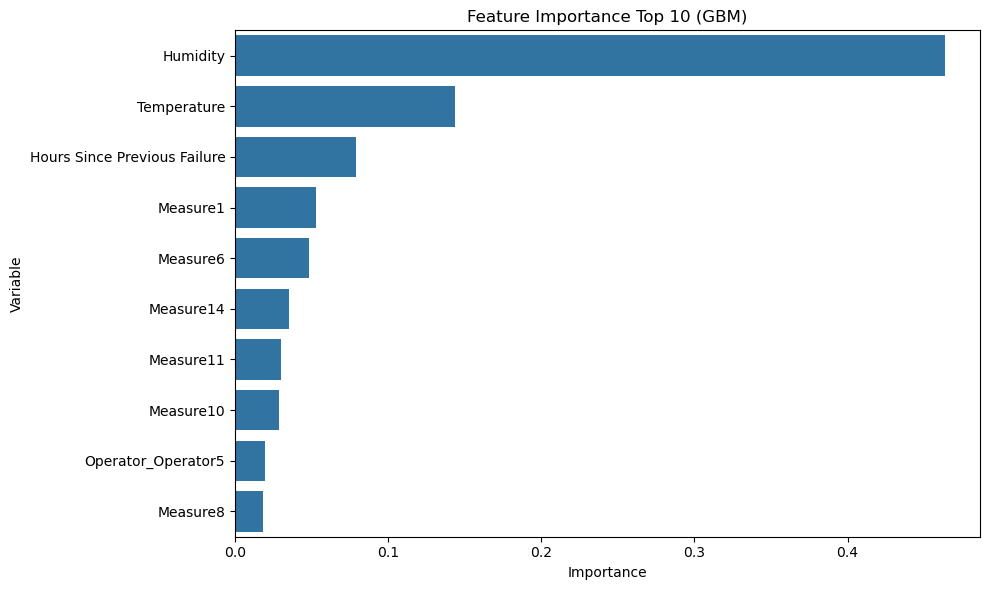

In [5]:
var_imp_gbm_cls = pd.DataFrame({"Variable": X_train.columns, "Importance": GBM_cls.feature_importances_})
imp_top10_gbm_cls = var_imp_gbm_cls.sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Variable", data=imp_top10_gbm_cls)
plt.title("Feature Importance Top 10 (GBM)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

> GBM의 주요 하이퍼 파라미터:
>
> | 하이퍼파라미터 | 기본값 | 하이퍼파라미터 설명 |
> |:---:|:---:|:---:|
> | learning_rate | 0.1 | 이전 오차를 얼마나 반영할지 결정 |
> | subsample | 1.0 | 각 트리 학습 시 사용할 데이터 비율 |
> | validation_fraction | 0.1 | 조기 종료를 위한 검증 데이터 비율 |
> | n_iter_no_change | None | 성능 향상이 없을 경우 학습 중단 |
> | n_estimators | 100 | 생성할 트리의 개수 |
> | max_depth | 3 | 트리의 최대 깊이 |
> | max_leaf_nodes | None | 리프 노드의 최대 개수 |
> | min_samples_leaf | 1 | 리프 노드가 되기 위한 최소 샘플 수 |
> | min_samples_split | 2 | 노드를 분할하기 위한 최소 샘플 수 |

In [6]:
params_gbm_cls = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "min_samples_leaf": [1, 5],
    "subsample": [0.8, 1.0]
}

grid_gbm_cls = GridSearchCV(
    GradientBoostingClassifier(random_state=0),
    param_grid=params_gbm_cls, cv=3, scoring="f1", n_jobs=-1
)
grid_gbm_cls.fit(X_train, Y_train)

print("최적 파라미터:", grid_gbm_cls.best_params_)
print("최적 F1-score (CV): %.4f" % grid_gbm_cls.best_score_)

최적 파라미터: {'learning_rate': 0.01, 'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 300, 'subsample': 0.8}
최적 F1-score (CV): 0.8291


In [7]:
best_gbm_cls_pred = grid_gbm_cls.predict(X_test)
print("[GBM - 최적 모델]")
get_classscore(Y_test, best_gbm_cls_pred)

[GBM - 최적 모델]
Accuracy  : 0.997
Precision : 0.944
Recall    : 0.773
F1-score  : 0.850


---

### 1-2) XGBoost

> **XGBoost**는 GBM에 **트리 규제항(Regularization)** 을 추가하여 과적합을 방지하는 모델임

In [8]:
XGB_cls = XGBClassifier()
XGB_cls.fit(X_train, Y_train)
XGB_cls_pred = XGB_cls.predict(X_test)
get_classscore(Y_test, XGB_cls_pred)

Accuracy  : 0.997
Precision : 1.000
Recall    : 0.682
F1-score  : 0.811


#### 변수 중요도 시각화

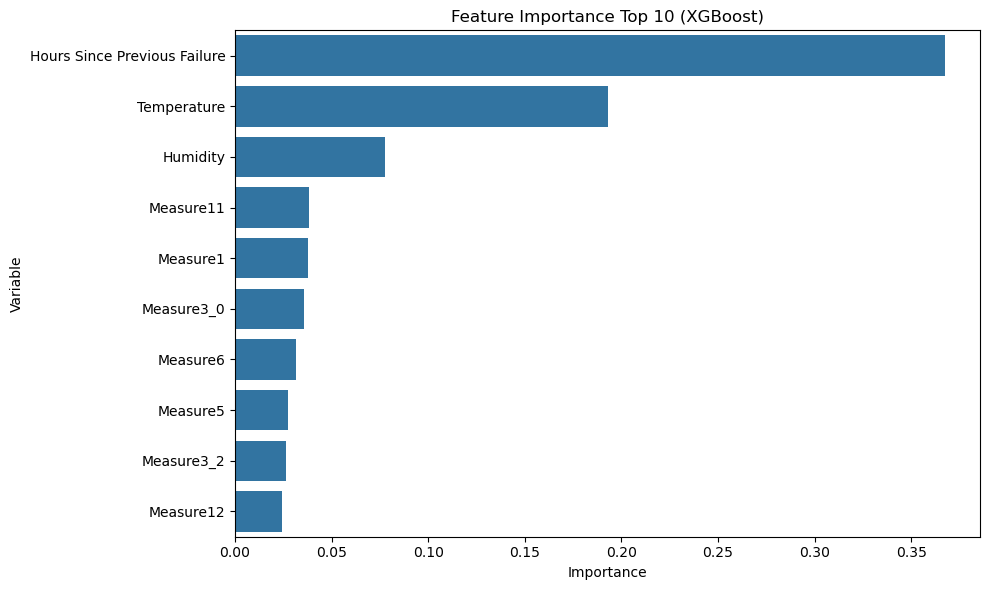

In [9]:
var_imp_xgb_cls = pd.DataFrame({"Variable": X_train.columns, "Importance": XGB_cls.feature_importances_})
imp_top10_xgb_cls = var_imp_xgb_cls.sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Variable", data=imp_top10_xgb_cls)
plt.title("Feature Importance Top 10 (XGBoost)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

> XGBoost의 주요 하이퍼 파라미터:
>
> | 하이퍼파라미터 | 기본값 | 하이퍼파라미터 설명 |
> |:---:|:---:|:---:|
> | colsample_bytree | 1.0 | 각 트리 학습 시 사용할 변수 비율 |
> | gamma | 0.0 | 추가 분할을 수행할 최소 기준 값 (클수록 단순한 모델 생성) |
> | reg_lambda | 1.0 | 과적합 방지를 위한 정규화 강도 |
> | n_estimators | 100 | 생성할 트리의 개수 |
> | max_depth | 6 | 트리의 최대 깊이 |
> | learning_rate | 0.1 | 각 트리가 이전 오차를 얼마나 반영할지 결정 |

In [10]:
params_xgb_cls = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "gamma": [0, 2],
    "reg_lambda": [1, 5],
    "subsample": [0.8, 1.0]
}

grid_xgb_cls = GridSearchCV(
    XGBClassifier(random_state=0, eval_metric="logloss"),
    param_grid=params_xgb_cls, cv=3, scoring="f1", n_jobs=-1
)
grid_xgb_cls.fit(X_train, Y_train)

print("최적 파라미터:", grid_xgb_cls.best_params_)
print("최적 F1-score (CV): %.4f" % grid_xgb_cls.best_score_)

최적 파라미터: {'gamma': 0, 'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 300, 'reg_lambda': 1, 'subsample': 1.0}
최적 F1-score (CV): 0.8335


In [11]:
best_xgb_cls_pred = grid_xgb_cls.predict(X_test)
print("[XGBoost - 최적 모델]")
get_classscore(Y_test, best_xgb_cls_pred)

[XGBoost - 최적 모델]
Accuracy  : 0.997
Precision : 1.000
Recall    : 0.727
F1-score  : 0.842


---

### 1-3) LightGBM

> **LightGBM**은 GBM의 학습 속도를 개선한 모델로, 다음 기술을 사용함
> - **GOSS** (Gradient-Based One Side Sampling): 잔차가 큰 데이터를 우선 학습하여 학습 데이터를 줄임
> - **Leaf-Wise Tree Growth**: 가장 큰 Loss를 가진 노드만 분할하여 트리 생성 속도를 높임
> - XGBoost 대비 최대 **38배 빠른 학습 속도**를 보이면서 비슷하거나 높은 정확도를 달성함

In [12]:
LGBM_cls = LGBMClassifier(verbose=-1)
LGBM_cls.fit(X_train, Y_train)
LGBM_cls_pred = LGBM_cls.predict(X_test)
get_classscore(Y_test, LGBM_cls_pred)

Accuracy  : 0.998
Precision : 1.000
Recall    : 0.773
F1-score  : 0.872


#### 변수 중요도 시각화

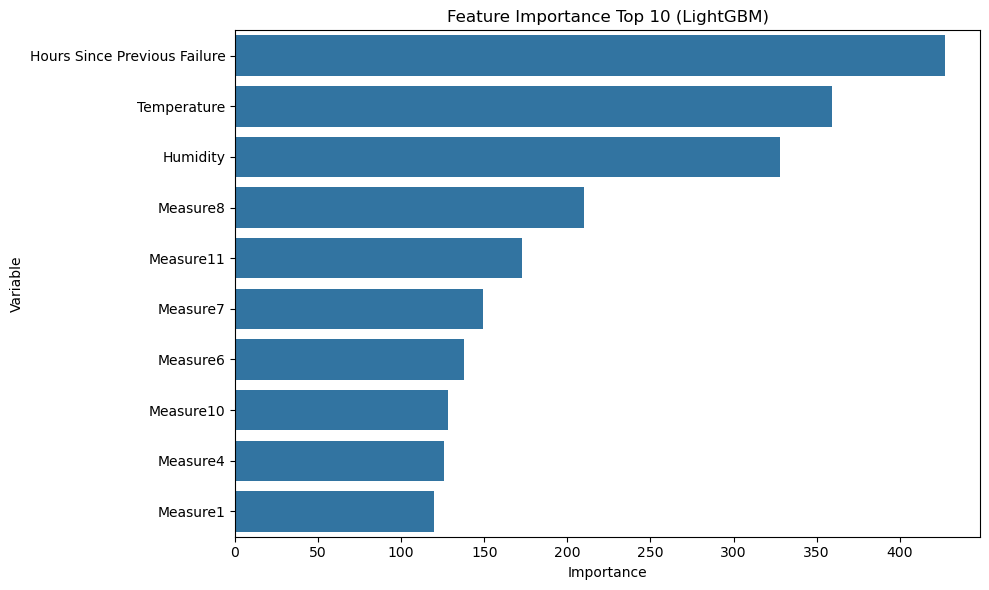

In [13]:
var_imp_lgbm_cls = pd.DataFrame({"Variable": X_train.columns, "Importance": LGBM_cls.feature_importances_})
imp_top10_lgbm_cls = var_imp_lgbm_cls.sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Variable", data=imp_top10_lgbm_cls)
plt.title("Feature Importance Top 10 (LightGBM)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

> LightGBM의 주요 하이퍼 파라미터:
>
> | 하이퍼파라미터 | 기본값 | 하이퍼파라미터 설명 |
> |:---:|:---:|:---:|
> | num_leaves | 31 | 하나의 트리가 가질 수 있는 최대 리프 노드 수 |
> | min_child_samples | 20 | 리프 노드가 되기 위한 최소 샘플 수 (min_samples_leaf와 거의 동일) |
> | n_estimators | 100 | 생성할 트리의 개수 |
> | max_depth | 6 | 트리의 최대 깊이 |
> | learning_rate | 0.1 | 각 트리가 이전 오차를 얼마나 반영할지 결정 |
> | colsample_bytree | 1.0 | 각 트리 학습 시 사용할 변수 비율 |

In [14]:
params_lgbm_cls = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "num_leaves": [15, 31],
    "min_child_samples": [20, 50],
    "subsample": [0.8, 1.0]
}

grid_lgbm_cls = GridSearchCV(
    LGBMClassifier(random_state=0, subsample_freq=1, verbose=-1),
    param_grid=params_lgbm_cls, cv=3, scoring="f1", n_jobs=-1
)
grid_lgbm_cls.fit(X_train, Y_train)

print("최적 파라미터:", grid_lgbm_cls.best_params_)
print("최적 F1-score (CV): %.4f" % grid_lgbm_cls.best_score_)

최적 파라미터: {'learning_rate': 0.1, 'max_depth': 3, 'min_child_samples': 20, 'n_estimators': 100, 'num_leaves': 15, 'subsample': 0.8}
최적 F1-score (CV): 0.8344


In [15]:
best_lgbm_cls_pred = grid_lgbm_cls.predict(X_test)
print("[LightGBM - 최적 모델]")
get_classscore(Y_test, best_lgbm_cls_pred)

[LightGBM - 최적 모델]
Accuracy  : 0.997
Precision : 0.941
Recall    : 0.727
F1-score  : 0.821


---

### 1-4) CatBoost

> **CatBoost**는 범주형 변수가 많은 데이터에서 좋은 성능을 보이는 GBM 계열 모델임
> - 별도의 One-Hot Encoding 없이 범주형 변수를 직접 처리할 수 있음

In [16]:
# CatBoost 전용: One-hot 인코딩 전 원본 데이터 사용

X_cat = MF_Data.drop(["Failure"], axis=1)

cat_features = ["Operator", "Measure2", "Measure3"]
for col in cat_features:
    X_cat[col] = X_cat[col].astype("category")

Xc_train, Xc_test, Yc_train, Yc_test = train_test_split(
    X_cat, Y, test_size=0.3, random_state=0, stratify=Y
)
print("CatBoost 학습 데이터 :", Xc_train.shape)
print("CatBoost 테스트 데이터 :", Xc_test.shape)

CatBoost 학습 데이터 : (5530, 19)
CatBoost 테스트 데이터 : (2370, 19)


In [17]:
CAT_cls = CatBoostClassifier(verbose=0)
# 범주형 변수 목록을 명시해야 category dtype 컬럼을 처리할 수 있음
CAT_cls.fit(Xc_train, Yc_train, cat_features=cat_features)

CAT_cls_pred = CAT_cls.predict(Xc_test)
get_classscore(Yc_test, CAT_cls_pred)

Accuracy  : 0.997
Precision : 1.000
Recall    : 0.727
F1-score  : 0.842


#### 변수 중요도 시각화

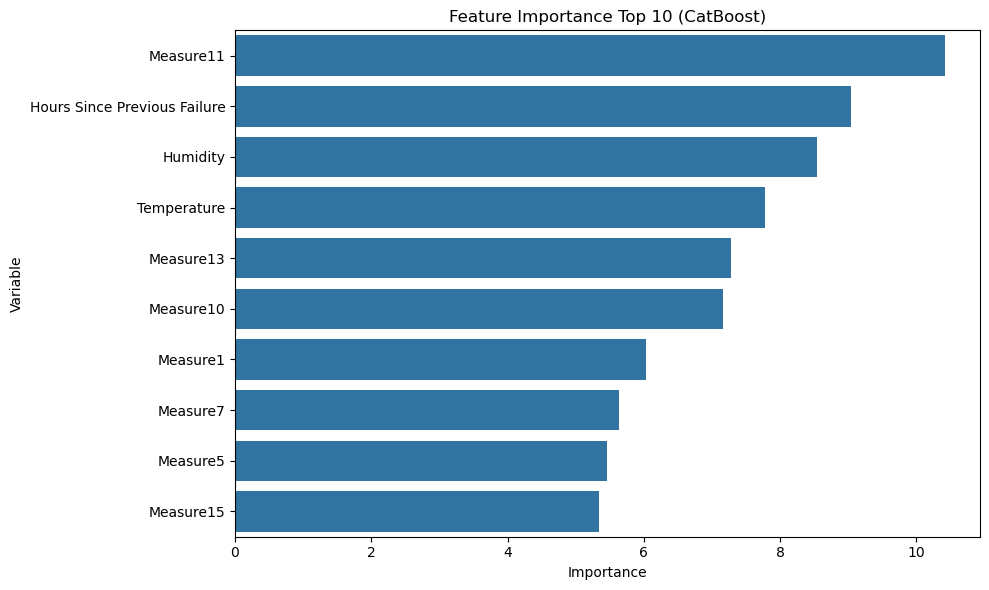

In [18]:
var_imp_cat_cls = pd.DataFrame({"Variable": Xc_train.columns, "Importance": CAT_cls.feature_importances_})
imp_top10_cat_cls = var_imp_cat_cls.sort_values(by="Importance", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Variable", data=imp_top10_cat_cls)
plt.title("Feature Importance Top 10 (CatBoost)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

> CatBoost의 주요 하이퍼 파라미터:
>
> | 하이퍼파라미터 | 기본값 | 하이퍼파라미터 설명 |
> |:---:|:---:|:---:|
> | l2_leaf_reg | 3.0 | 과적합 방지를 위한 정규화 강도 |
> | random_strength | 1.0 | 트리 생성 시 랜덤성을 부여하는 정도 |
> | bagging_temperature | 1.0 | 데이터 샘플링 강도 |
> | border_count | 254 | 연속형 변수를 구간화하는 개수 |
> | iteration | 100 | 생성할 트리의 개수 |
> | depth | 6 | 트리의 최대 깊이 |
> | learning_rate | 0.1 | 각 트리가 이전 오차를 얼마나 반영할지 결정 |

In [19]:
params_cat_cls = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "l2_leaf_reg": [1, 3, 5],
    "subsample": [0.8, 1.0]
}

grid_cat_cls = GridSearchCV(
    CatBoostClassifier(random_state=0, verbose=0, bootstrap_type="Bernoulli"),
    param_grid=params_cat_cls, cv=3, scoring="f1", n_jobs=-1
)
grid_cat_cls.fit(Xc_train, Yc_train, cat_features=cat_features)

print("최적 파라미터:", grid_cat_cls.best_params_)
print("최적 F1-score (CV): %.4f" % grid_cat_cls.best_score_)

최적 파라미터: {'l2_leaf_reg': 3, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0}
최적 F1-score (CV): 0.8515


In [20]:
best_cat_cls_pred = grid_cat_cls.predict(Xc_test)
print("[CatBoost - 최적 모델]")
get_classscore(Yc_test, best_cat_cls_pred)

[CatBoost - 최적 모델]
Accuracy  : 0.997
Precision : 1.000
Recall    : 0.727
F1-score  : 0.842


---

## 2. 회귀 (Regression) - Concrete 데이터

> 분류에서 다룬 GBM 계열 모델들은 **회귀** 문제에도 동일하게 적용할 수 있음
> - Classifier → Regressor로 변경하고, 평가 지표를 MSE, R-squared 등으로 변경함
> - 각 모델의 하이퍼 파라미터는 분류와 동일하게 적용됨

### 데이터 전처리

In [21]:
Concrete = pd.read_csv(os.path.join(os.getcwd(), "dataset", "day3-2_reg_data.csv"))

Y_reg = Concrete["Concrete_compressive_strength"]
X_reg = Concrete.drop(["Concrete_compressive_strength"], axis=1)

X_train_reg, X_test_reg, Y_train_reg, Y_test_reg = train_test_split(
    X_reg, Y_reg, test_size=0.3, random_state=0)

print("학습 데이터 :", X_train_reg.shape)
print("테스트 데이터 :", X_test_reg.shape)

학습 데이터 : (721, 8)
테스트 데이터 : (309, 8)


---

### 2-1) GBM

In [22]:
GBM_reg = GradientBoostingRegressor()
GBM_reg.fit(X_train_reg, Y_train_reg)
GBM_reg_pred = GBM_reg.predict(X_test_reg)
get_regscore(Y_test_reg, GBM_reg_pred)

MSE       : 26.271
RMSE      : 5.126
MAE       : 3.840
R-squared : 0.898


#### 변수 중요도 시각화

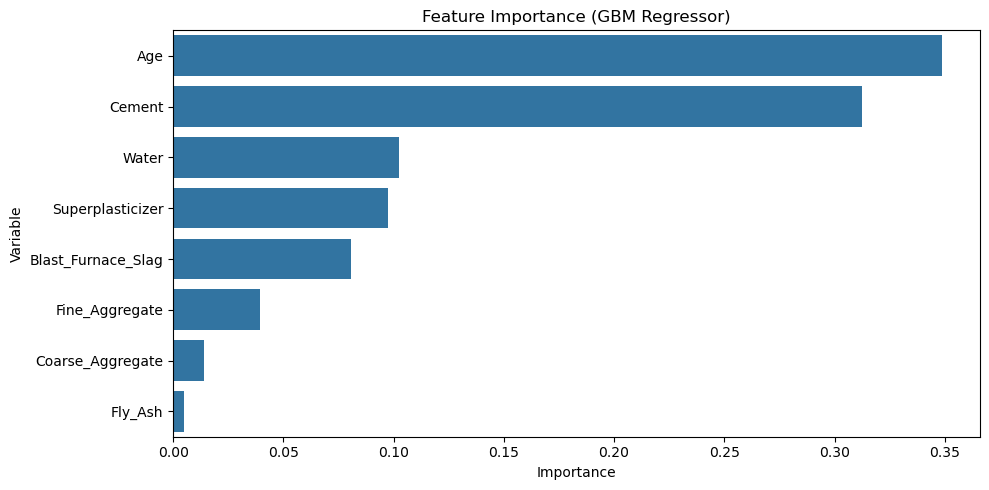

In [23]:
var_imp_gbm_reg = pd.DataFrame({"Variable": X_train_reg.columns, "Importance": GBM_reg.feature_importances_})
var_imp_gbm_reg = var_imp_gbm_reg.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Variable", data=var_imp_gbm_reg)
plt.title("Feature Importance (GBM Regressor)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

In [24]:
params_gbm_reg = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "min_samples_leaf": [1, 5],
    "subsample": [0.8, 1.0]
}

grid_gbm_reg = GridSearchCV(
    GradientBoostingRegressor(random_state=0),
    param_grid=params_gbm_reg, cv=3, scoring="r2", n_jobs=-1
)
grid_gbm_reg.fit(X_train_reg, Y_train_reg)

print("최적 파라미터:", grid_gbm_reg.best_params_)
print("최적 R-squared (CV): %.4f" % grid_gbm_reg.best_score_)

최적 파라미터: {'learning_rate': 0.1, 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 300, 'subsample': 0.8}
최적 R-squared (CV): 0.9140


In [25]:
best_gbm_reg_pred = grid_gbm_reg.predict(X_test_reg)
print("[GBM - 최적 모델]")
get_regscore(Y_test_reg, best_gbm_reg_pred)

[GBM - 최적 모델]
MSE       : 19.442
RMSE      : 4.409
MAE       : 3.069
R-squared : 0.924


---

### 2-2) XGBoost

In [26]:
XGB_reg = XGBRegressor()
XGB_reg.fit(X_train_reg, Y_train_reg)
XGB_reg_pred = XGB_reg.predict(X_test_reg)
get_regscore(Y_test_reg, XGB_reg_pred)

MSE       : 22.102
RMSE      : 4.701
MAE       : 3.161
R-squared : 0.914


#### 변수 중요도 시각화

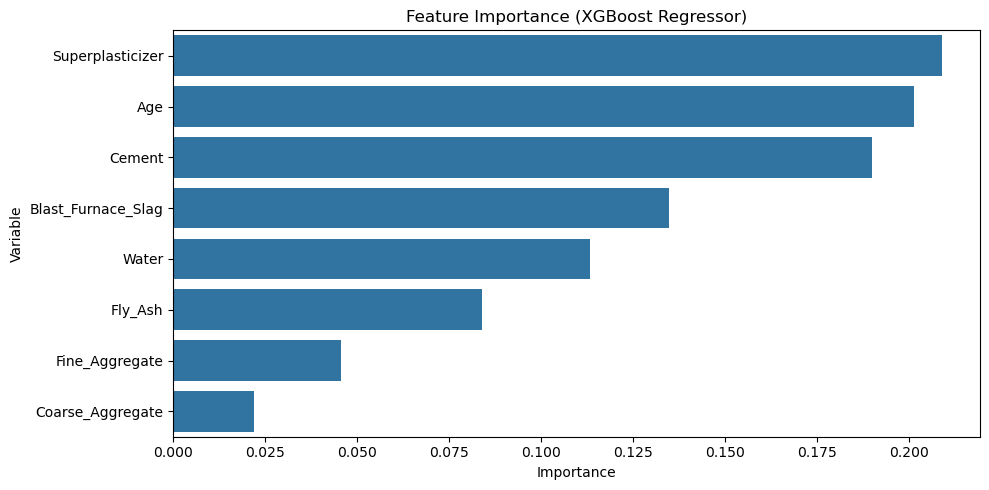

In [27]:
var_imp_xgb_reg = pd.DataFrame({"Variable": X_train_reg.columns, "Importance": XGB_reg.feature_importances_})
var_imp_xgb_reg = var_imp_xgb_reg.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Variable", data=var_imp_xgb_reg)
plt.title("Feature Importance (XGBoost Regressor)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

In [28]:
params_xgb_reg = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "gamma": [0, 2],
    "reg_lambda": [1, 5],
    "subsample": [0.8, 1.0]
}

grid_xgb_reg = GridSearchCV(
    XGBRegressor(random_state=0),
    param_grid=params_xgb_reg, cv=3, scoring="r2", n_jobs=-1
)
grid_xgb_reg.fit(X_train_reg, Y_train_reg)

print("최적 파라미터:", grid_xgb_reg.best_params_)
print("최적 R-squared (CV): %.4f" % grid_xgb_reg.best_score_)

최적 파라미터: {'gamma': 0, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300, 'reg_lambda': 5, 'subsample': 0.8}
최적 R-squared (CV): 0.9144


In [29]:
best_xgb_reg_pred = grid_xgb_reg.predict(X_test_reg)
print("[XGBoost - 최적 모델]")
get_regscore(Y_test_reg, best_xgb_reg_pred)

[XGBoost - 최적 모델]
MSE       : 20.833
RMSE      : 4.564
MAE       : 3.248
R-squared : 0.919


---

### 2-3) LightGBM

In [30]:
LGBM_reg = LGBMRegressor(verbose=-1)
LGBM_reg.fit(X_train_reg, Y_train_reg)
LGBM_reg_pred = LGBM_reg.predict(X_test_reg)
get_regscore(Y_test_reg, LGBM_reg_pred)

MSE       : 21.353
RMSE      : 4.621
MAE       : 3.244
R-squared : 0.917


#### 변수 중요도 시각화

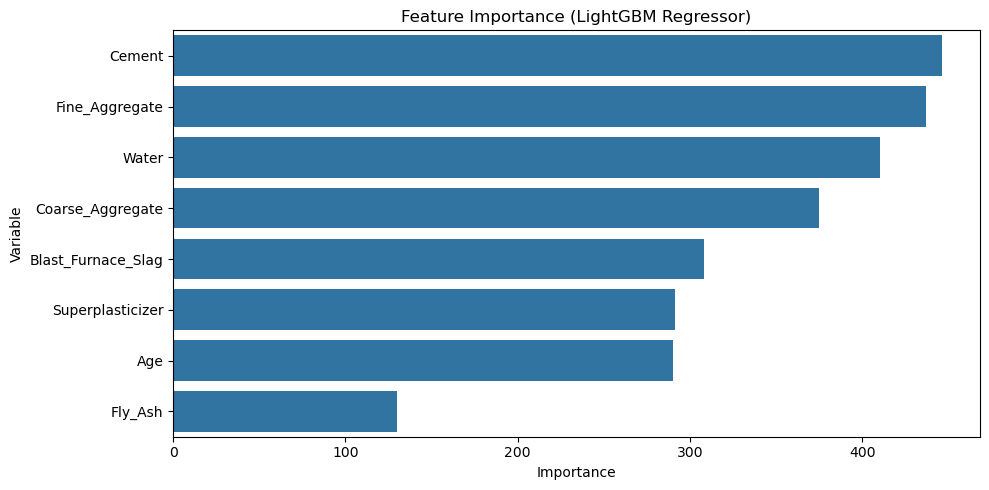

In [31]:
var_imp_lgbm_reg = pd.DataFrame({"Variable": X_train_reg.columns, "Importance": LGBM_reg.feature_importances_})
var_imp_lgbm_reg = var_imp_lgbm_reg.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Variable", data=var_imp_lgbm_reg)
plt.title("Feature Importance (LightGBM Regressor)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

In [32]:
params_lgbm_reg = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "num_leaves": [15, 31],
    "min_child_samples": [20, 50],
    "subsample": [0.8, 1.0]
}

grid_lgbm_reg = GridSearchCV(
    LGBMRegressor(random_state=0, verbose=-1),
    param_grid=params_lgbm_reg, cv=3, scoring="r2", n_jobs=-1
)
grid_lgbm_reg.fit(X_train_reg, Y_train_reg)

print("최적 파라미터:", grid_lgbm_reg.best_params_)
print("최적 R-squared (CV): %.4f" % grid_lgbm_reg.best_score_)

최적 파라미터: {'learning_rate': 0.1, 'max_depth': 5, 'min_child_samples': 20, 'n_estimators': 300, 'num_leaves': 15, 'subsample': 0.8}
최적 R-squared (CV): 0.9119


In [33]:
best_lgbm_reg_pred = grid_lgbm_reg.predict(X_test_reg)
print("[LightGBM - 최적 모델]")
get_regscore(Y_test_reg, best_lgbm_reg_pred)

[LightGBM - 최적 모델]
MSE       : 20.376
RMSE      : 4.514
MAE       : 3.080
R-squared : 0.921


---

### 2-4) CatBoost

In [34]:
CAT_reg = CatBoostRegressor(verbose=0)
# 해당 데이터셋에는 범주형이 없어서 따로 cat_features를 지정하지 않아도 동작 가능
CAT_reg.fit(X_train_reg, Y_train_reg)
CAT_reg_pred = CAT_reg.predict(X_test_reg)
get_regscore(Y_test_reg, CAT_reg_pred)

MSE       : 17.915
RMSE      : 4.233
MAE       : 2.778
R-squared : 0.930


#### 변수 중요도 시각화

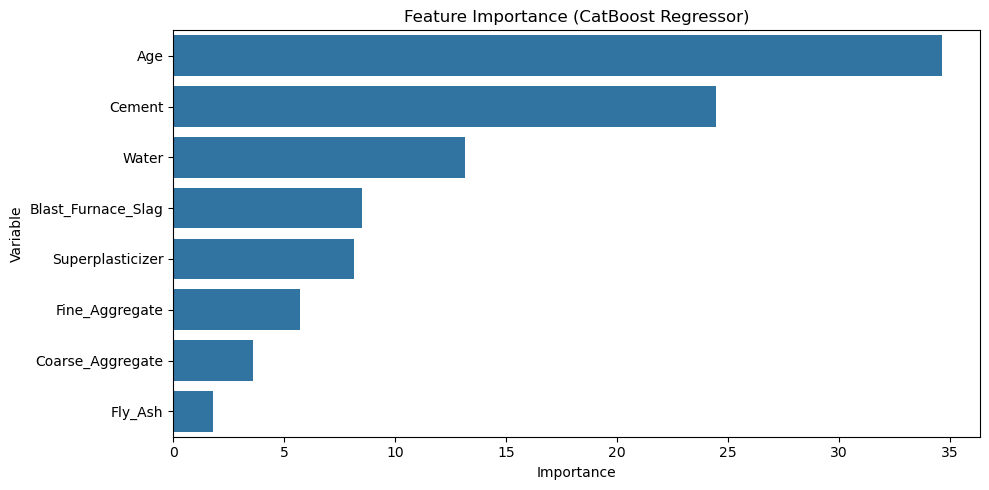

In [35]:
var_imp_cat_reg = pd.DataFrame({"Variable": X_train_reg.columns, "Importance": CAT_reg.feature_importances_})
var_imp_cat_reg = var_imp_cat_reg.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Variable", data=var_imp_cat_reg)
plt.title("Feature Importance (CatBoost Regressor)")
plt.tight_layout()
plt.show()

#### 하이퍼 파라미터 최적화

In [36]:
params_cat_reg = {
    "n_estimators": [100, 300],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [3, 5],
    "l2_leaf_reg": [1, 3, 5]
}

grid_cat_reg = GridSearchCV(
    CatBoostRegressor(random_state=0, verbose=0),
    param_grid=params_cat_reg, cv=3, scoring="r2"
)
grid_cat_reg.fit(X_train_reg, Y_train_reg)

print("최적 파라미터:", grid_cat_reg.best_params_)
print("최적 R-squared (CV): %.4f" % grid_cat_reg.best_score_)

최적 파라미터: {'l2_leaf_reg': 3, 'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}
최적 R-squared (CV): 0.9242


In [37]:
best_cat_reg_pred = grid_cat_reg.predict(X_test_reg)
print("[CatBoost - 최적 모델]")
get_regscore(Y_test_reg, best_cat_reg_pred)

[CatBoost - 최적 모델]
MSE       : 20.723
RMSE      : 4.552
MAE       : 3.117
R-squared : 0.919


---

In [38]:
best_models_cls = {
    "GBM": best_gbm_cls_pred,
    "XGBoost": best_xgb_cls_pred,
    "LightGBM": best_lgbm_cls_pred,
    "CatBoost": best_cat_cls_pred
}

best_results_cls = []
for name, pred in best_models_cls.items():
    true = Yc_test if name == "CatBoost" else Y_test
    best_results_cls.append({
        "Model": name,
        "Accuracy": round(accuracy_score(true, pred), 3),
        "Precision": round(precision_score(true, pred), 3),
        "Recall": round(recall_score(true, pred), 3),
        "F1-score": round(f1_score(true, pred), 3)
    })

pd.DataFrame(best_results_cls)

,Model,Accuracy,Precision,Recall,F1-score
0,GBM,0.997,0.944,0.773,0.850
1,XGBoost,0.997,1.000,0.727,0.842
2,LightGBM,0.997,0.941,0.727,0.821
3,CatBoost,0.997,1.000,0.727,0.842


In [39]:
best_models_reg = {
    "GBM": best_gbm_reg_pred,
    "XGBoost": best_xgb_reg_pred,
    "LightGBM": best_lgbm_reg_pred,
    "CatBoost": best_cat_reg_pred
}

best_results_reg = []
for name, pred in best_models_reg.items():
    best_results_reg.append({
        "Model": name,
        "RMSE": round(np.sqrt(mean_squared_error(Y_test_reg, pred)), 3),
        "MAE": round(mean_absolute_error(Y_test_reg, pred), 3),
        "R-squared": round(r2_score(Y_test_reg, pred), 3)
    })

pd.DataFrame(best_results_reg)

,Model,RMSE,MAE,R-squared
0,GBM,4.409,3.069,0.924
1,XGBoost,4.564,3.248,0.919
2,LightGBM,4.514,3.080,0.921
3,CatBoost,4.552,3.117,0.919


---

## 3. Vibe Coding 실습

**[과제 1]** 지수는 LightGBM이 XGBoost보다 빠르게 학습된다는 설명을 들었지만, 실제로 얼마나 차이가 나는지 궁금했습니다. AI와 상의하여 동일한 데이터셋(회귀 또는 분류)으로 XGBoost와 LightGBM을 학습시키고 학습 시간과 예측 성능을 비교해 보세요.

**[과제 2]** 지수는 GBM, XGBoost, LightGBM, CatBoost가 같은 데이터를 학습했지만, 각 모델이 중요하게 판단하는 변수는 다를 수 있다고 생각했습니다. AI와 함께 회귀 또는 분류 문제에서 네 모델의 변수 중요도를 한눈에 비교할 수 있는 시각화 방법을 상의하고, 실제로 비교하여 모델 간 중요도 순위가 얼마나 일치하는지 확인해 보세요.

In [40]:
# ============================================================
# 1. 모델별 주요 변수(피처 중요도) 산출
# ============================================================

# (이미 학습했다면 아래 4줄은 생략)
GBM_reg = GradientBoostingRegressor(random_state=0)
XGB_reg = XGBRegressor(random_state=0)
LGBM_reg = LGBMRegressor(random_state=0, verbose=-1)
CAT_reg = CatBoostRegressor(random_state=0, verbose=0)

GBM_reg.fit(X_train_reg, Y_train_reg)
XGB_reg.fit(X_train_reg, Y_train_reg)
LGBM_reg.fit(X_train_reg, Y_train_reg)
CAT_reg.fit(X_train_reg, Y_train_reg)

# 모델 이름과 객체 매핑
models = {
    "GBM": GBM_reg,
    "XGBoost": XGB_reg,
    "LightGBM": LGBM_reg,
    "CatBoost": CAT_reg,
}

feature_names = X_train_reg.columns.tolist()

# 모델별 중요도 DataFrame (열 = 모델)
importance_raw = pd.DataFrame(index=feature_names)
for name, model in models.items():
    importance_raw[name] = model.feature_importances_

# 모델별 합 = 1 로 정규화 (스케일 차이 보정)
importance_norm = importance_raw.div(importance_raw.sum(axis=0), axis=1)

print("=== 정규화된 변수 중요도 (전체) ===")
print(importance_norm.round(4))

# 모델별 Top 5 변수
print("\n=== 모델별 Top 5 변수 ===")
for name in models:
    top5 = importance_norm[name].sort_values(ascending=False).head(5)
    print(f"\n[{name}]")
    for var, imp in top5.items():
        print(f"  {var}: {imp:.4f}")

# long format (시각화용)
imp_long = importance_norm.reset_index().melt(
    id_vars="index", var_name="Model", value_name="Importance"
)
imp_long.rename(columns={"index": "Variable"}, inplace=True)

=== 정규화된 변수 중요도 (전체) ===
                       GBM  XGBoost  LightGBM  CatBoost
Cement              0.3127   0.1900    0.1660    0.2448
Blast_Furnace_Slag  0.0806   0.1348    0.1146    0.0849
Fly_Ash             0.0051   0.0840    0.0484    0.0181
Water               0.1020   0.1132    0.1526    0.1315
Superplasticizer    0.0973   0.2089    0.1083    0.0813
Coarse_Aggregate    0.0141   0.0219    0.1396    0.0361
Fine_Aggregate      0.0396   0.0457    0.1626    0.0571
Age                 0.3486   0.2014    0.1079    0.3463

=== 모델별 Top 5 변수 ===

[GBM]
  Age: 0.3486
  Cement: 0.3127
  Water: 0.1020
  Superplasticizer: 0.0973
  Blast_Furnace_Slag: 0.0806

[XGBoost]
  Superplasticizer: 0.2089
  Age: 0.2014
  Cement: 0.1900
  Blast_Furnace_Slag: 0.1348
  Water: 0.1132

[LightGBM]
  Cement: 0.1660
  Fine_Aggregate: 0.1626
  Water: 0.1526
  Coarse_Aggregate: 0.1396
  Blast_Furnace_Slag: 0.1146

[CatBoost]
  Age: 0.3463
  Cement: 0.2448
  Water: 0.1315
  Blast_Furnace_Slag: 0.0849
  Superplas

C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\3278995781.py:37: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from fo

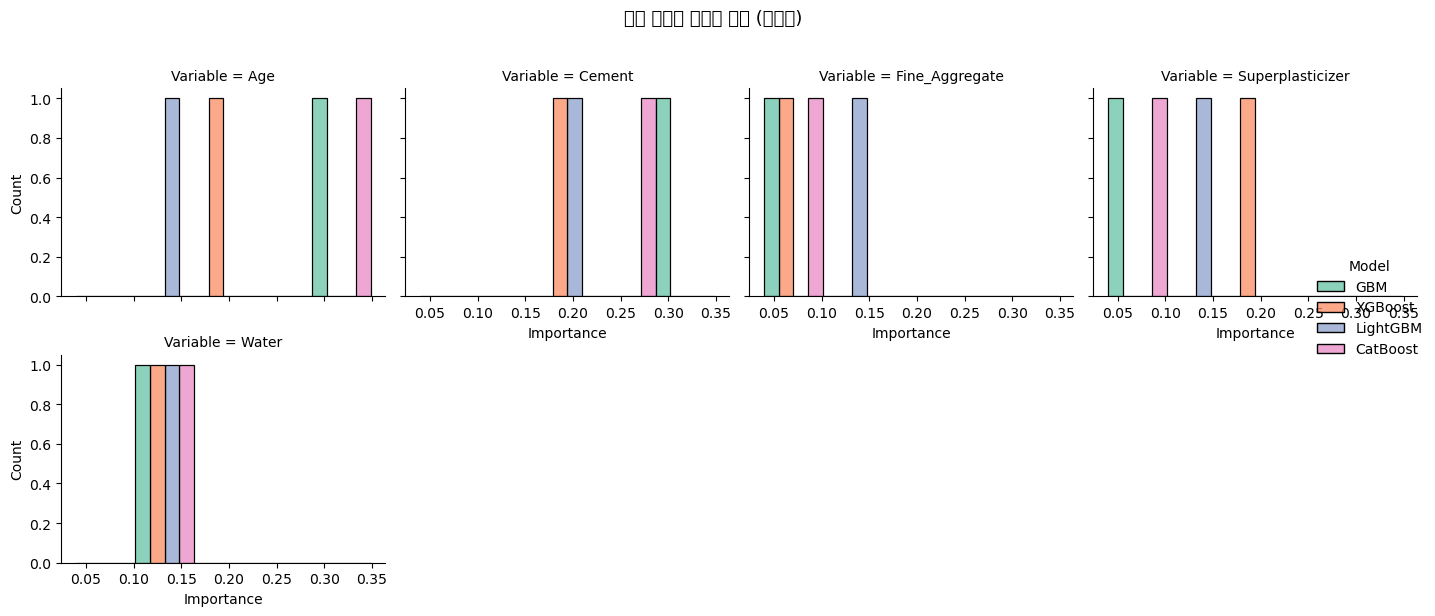

In [41]:
# ============================================================
# 2. 주요 변수별 중요도 — 모델별 legend 히스토그램
# ============================================================

TOP_K = 3   # 모델당 상위 k개 변수를 모아 비교

# 비교할 변수 목록 (모델별 top k 합집합)
top_vars = set()
for name in models:
    top_vars.update(
        importance_norm[name].sort_values(ascending=False).head(TOP_K).index
    )
top_vars = sorted(top_vars)

# 비교 대상만 필터
imp_compare = imp_long[imp_long["Variable"].isin(top_vars)].copy()
imp_compare["Variable"] = pd.Categorical(
    imp_compare["Variable"], categories=top_vars, ordered=True
)

# --- (A) 변수별 그룹 히스토그램: x=중요도, hue=모델, col=변수 ---
g = sns.displot(
    data=imp_compare,
    x="Importance",
    hue="Model",
    col="Variable",
    col_wrap=4,
    height=3,
    aspect=1.1,
    kde=False,
    bins=5,
    element="bars",
    multiple="dodge",
    palette="Set2",
)
g.fig.suptitle("주요 변수별 중요도 분포 (모델별)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 52404 (\N{HANGUL SYLLABLE CE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\1559155428.py:27: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s

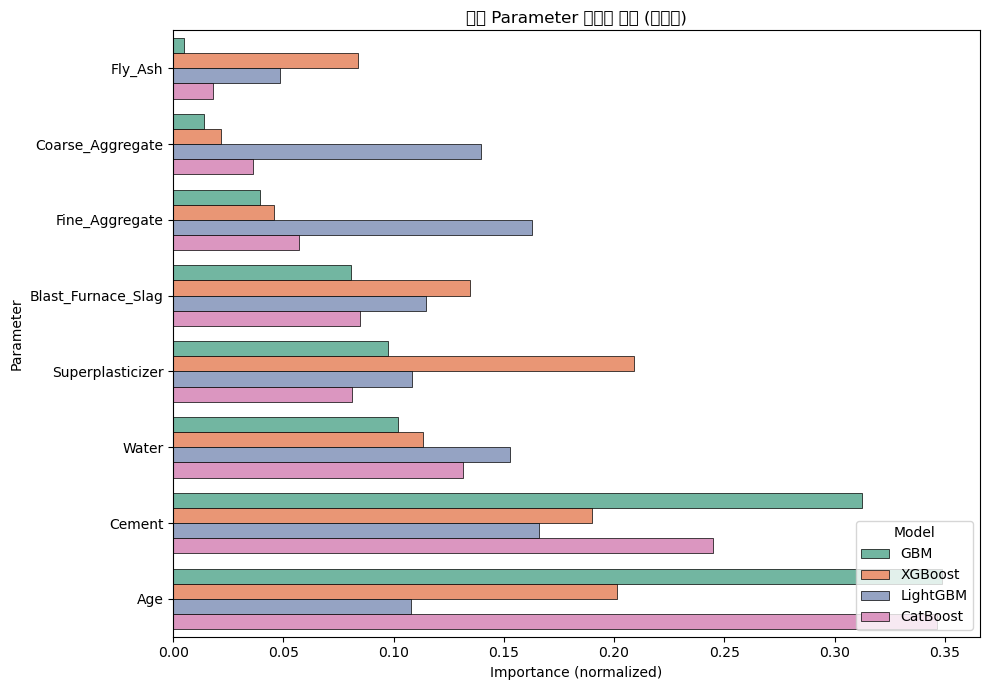

In [43]:
# 전체 변수 버전
var_order_all = (
    imp_long.groupby("Variable")["Importance"]
    .mean()
    .sort_values(ascending=True)
    .index.tolist()
)
imp_all = imp_long.copy()
imp_all["Variable"] = pd.Categorical(
    imp_all["Variable"], categories=var_order_all, ordered=True
)

plt.figure(figsize=(10, 7))
sns.barplot(
    data=imp_all,
    y="Variable",
    x="Importance",
    hue="Model",
    palette="Set2",
    edgecolor="black",
    linewidth=0.5,
)
plt.title("전체 Parameter 중요도 비교 (모델별)")
plt.xlabel("Importance (normalized)")
plt.ylabel("Parameter")
plt.legend(title="Model", loc="lower right")
plt.tight_layout()
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 50836 (\N{HANGUL SYLLABLE YO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 48320 (\N{HANGUL SYLLABLE BYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Admin\AppData\Local\Temp\ipykernel_2884\2930125946.py:14: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(

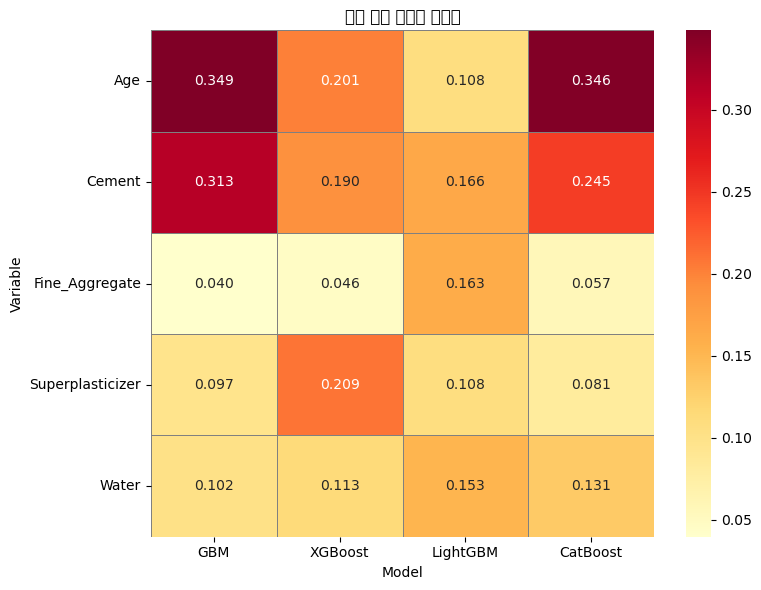

In [42]:
# ============================================================
# 3. (선택) 변수 × 모델 히트맵
# ============================================================

plt.figure(figsize=(8, 6))
sns.heatmap(
    importance_norm.loc[top_vars],
    annot=True, fmt=".3f", cmap="YlOrRd",
    linewidths=0.5, linecolor="gray"
)
plt.title("주요 변수 중요도 히트맵")
plt.ylabel("Variable")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

**[과제 3]** 지수는 여러 머신러닝 모델의 예측 결과를 결합하는 Stacking Ensemble이라는 방법을 알게 되었고, Stacking 모델이 단일 앙상블 모델보다 항상 더 좋은 성능을 보이는지 궁금해졌습니다. AI와 상의하여 결합할 모델들을 선택해 Stacking 모델을 구축해 보세요. 이후 Stacking 모델과 각 단일 앙상블 모델의 성능을 비교해 보세요.

In [44]:
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

base_models = [
    ("gbm",  GradientBoostingRegressor(random_state=0)),
    ("xgb",  XGBRegressor(random_state=0)),
    ("lgbm", LGBMRegressor(random_state=0, verbose=-1)),
    ("cat",  CatBoostRegressor(random_state=0, verbose=0)),
]

In [45]:
meta_model = Ridge(alpha=1.0)

In [46]:
stacking_reg = StackingRegressor(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,                    # ★ 핵심: meta 학습용 교차검증
    passthrough=False,       # True면 원본 X도 meta에 함께 전달
    n_jobs=-1
)

In [47]:
stacking_reg.fit(X_train_reg, Y_train_reg)
stack_pred = stacking_reg.predict(X_test_reg)
get_regscore(Y_test_reg, stack_pred)

MSE       : 18.218
RMSE      : 4.268
MAE       : 2.739
R-squared : 0.929


In [48]:
for name, model in base_models:
    model.fit(X_train_reg, Y_train_reg)
    pred = model.predict(X_test_reg)
    print(f"{name}: R² = {r2_score(Y_test_reg, pred):.4f}")

print(f"stacking: R² = {r2_score(Y_test_reg, stack_pred):.4f}")

gbm: R² = 0.8986
xgb: R² = 0.9139
lgbm: R² = 0.9168
cat: R² = 0.9302
stacking: R² = 0.9290


=== Ridge alpha별 Stacking 성능 ===
    alpha  train_r2  test_r2  test_rmse  test_mae
    0.001    0.9897   0.9290     4.2684    2.7386
    0.010    0.9897   0.9290     4.2684    2.7386
    0.100    0.9897   0.9290     4.2684    2.7386
    1.000    0.9897   0.9290     4.2682    2.7385
   10.000    0.9897   0.9291     4.2665    2.7375
  100.000    0.9899   0.9296     4.2507    2.7283
 1000.000    0.9903   0.9319     4.1815    2.7120
10000.000    0.9883   0.9305     4.2234    2.8854

Test R² 최고 alpha: 1000.0
alpha        1000.000000
train_r2        0.990300
test_r2         0.931887
test_rmse       4.181464
test_mae        2.711970
Name: 6, dtype: float64


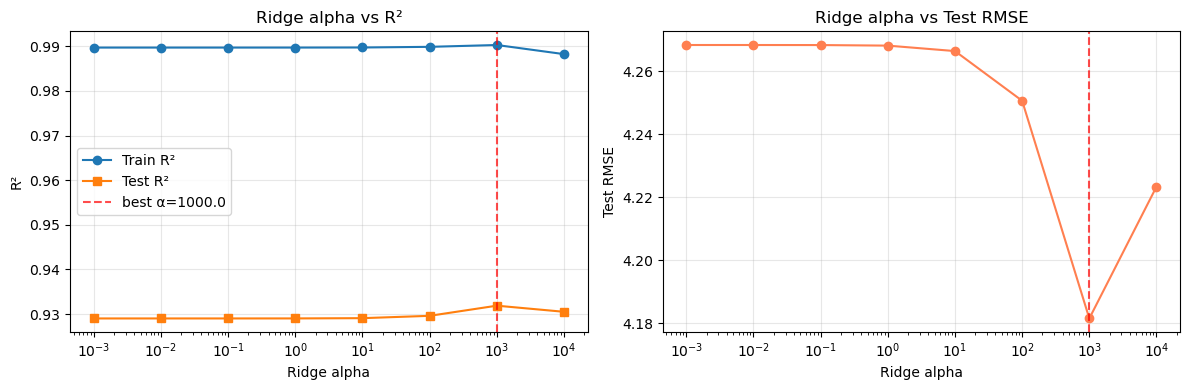


=== Meta 모델(Ridge) base별 가중치 ===
  gbm: -0.1304
  xgb: 0.1492
  lgbm: 0.0857
  cat: 0.9131

=== 최종 Stacking (Test) ===
MSE       : 17.485
RMSE      : 4.181
MAE       : 2.712
R-squared : 0.932


In [49]:
from sklearn.ensemble import StackingRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge, RidgeCV
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# ============================================================
# Stacking + Ridge alpha 탐색
# ============================================================

# 1) Base models (튜닝했다면 best_params 반영)
base_models = [
    ("gbm",  GradientBoostingRegressor(random_state=0)),
    ("xgb",  XGBRegressor(random_state=0)),
    ("lgbm", LGBMRegressor(random_state=0, verbose=-1)),
    ("cat",  CatBoostRegressor(random_state=0, verbose=0)),
]

# 2) 탐색할 alpha 목록
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

results = []

for alpha in alphas:
    stacking = StackingRegressor(
        estimators=base_models,
        final_estimator=Ridge(alpha=alpha),
        cv=5,
        passthrough=False,
        n_jobs=-1,
    )
    stacking.fit(X_train_reg, Y_train_reg)

    train_pred = stacking.predict(X_train_reg)
    test_pred  = stacking.predict(X_test_reg)

    results.append({
        "alpha": alpha,
        "train_r2":  r2_score(Y_train_reg, train_pred),
        "test_r2":   r2_score(Y_test_reg, test_pred),
        "test_rmse": np.sqrt(mean_squared_error(Y_test_reg, test_pred)),
        "test_mae":  mean_absolute_error(Y_test_reg, test_pred),
    })

result_df = pd.DataFrame(results)
print("=== Ridge alpha별 Stacking 성능 ===")
print(result_df.round(4).to_string(index=False))

# 3) 최적 alpha (Test R² 기준)
best_idx = result_df["test_r2"].idxmax()
best_alpha = result_df.loc[best_idx, "alpha"]
print(f"\nTest R² 최고 alpha: {best_alpha}")
print(result_df.loc[best_idx])

# 4) 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].semilogx(result_df["alpha"], result_df["train_r2"], "o-", label="Train R²")
axes[0].semilogx(result_df["alpha"], result_df["test_r2"],  "s-", label="Test R²")
axes[0].axvline(best_alpha, color="red", linestyle="--", alpha=0.7, label=f"best α={best_alpha}")
axes[0].set_xlabel("Ridge alpha")
axes[0].set_ylabel("R²")
axes[0].set_title("Ridge alpha vs R²")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].semilogx(result_df["alpha"], result_df["test_rmse"], "o-", color="coral")
axes[1].axvline(best_alpha, color="red", linestyle="--", alpha=0.7)
axes[1].set_xlabel("Ridge alpha")
axes[1].set_ylabel("Test RMSE")
axes[1].set_title("Ridge alpha vs Test RMSE")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 5) 최적 alpha로 최종 모델 + meta 계수 확인
best_stack = StackingRegressor(
    estimators=base_models,
    final_estimator=Ridge(alpha=best_alpha),
    cv=5,
    passthrough=False,
    n_jobs=-1,
)
best_stack.fit(X_train_reg, Y_train_reg)

coef = best_stack.final_estimator_.coef_
print("\n=== Meta 모델(Ridge) base별 가중치 ===")
for name, w in zip([m[0] for m in base_models], coef):
    print(f"  {name}: {w:.4f}")

print("\n=== 최종 Stacking (Test) ===")
get_regscore(Y_test_reg, best_stack.predict(X_test_reg))

In [51]:
print(result_df.round(4))

       alpha  train_r2  test_r2  test_rmse  test_mae
0      0.001    0.9897   0.9290     4.2684    2.7386
1      0.010    0.9897   0.9290     4.2684    2.7386
2      0.100    0.9897   0.9290     4.2684    2.7386
3      1.000    0.9897   0.9290     4.2682    2.7385
4     10.000    0.9897   0.9291     4.2665    2.7375
5    100.000    0.9899   0.9296     4.2507    2.7283
6   1000.000    0.9903   0.9319     4.1815    2.7120
7  10000.000    0.9883   0.9305     4.2234    2.8854


In [50]:
ridge_cv = RidgeCV(alphas=alphas, cv=5)

stack_cv = StackingRegressor(
    estimators=base_models,
    final_estimator=ridge_cv,
    cv=5,
    passthrough=False,
    n_jobs=-1,
)
stack_cv.fit(X_train_reg, Y_train_reg)

print("RidgeCV 선택 alpha:", stack_cv.final_estimator_.alpha_)
get_regscore(Y_test_reg, stack_cv.predict(X_test_reg))

RidgeCV 선택 alpha: 10.0
MSE       : 18.203
RMSE      : 4.266
MAE       : 2.737
R-squared : 0.929


        gbm    xgb   lgbm    cat
gbm   1.000  0.978  0.987  0.987
xgb   0.978  1.000  0.984  0.984
lgbm  0.987  0.984  1.000  0.989
cat   0.987  0.984  0.989  1.000


c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45230 (\N{HANGUL SYLLABLE NAJ}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 51012 (\N{HANGUL SYLLABLE EUL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 49688 (\N{HANGUL SYLLABLE SU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Admin\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 45796 (\N{HANGUL SYLLABLE DA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io

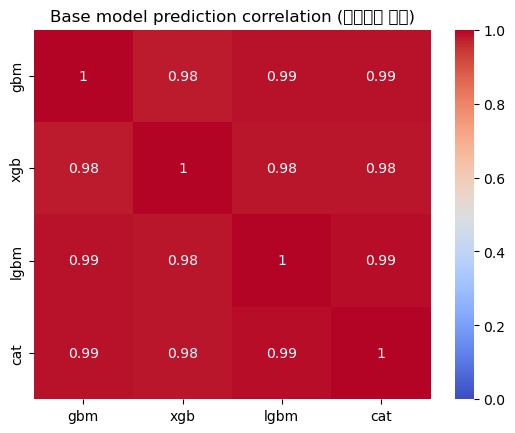

In [52]:
# Train에서 OOF 또는 validation 예측으로 상관행렬
from sklearn.model_selection import cross_val_predict

preds = {}
for name, model in base_models:
    pred = cross_val_predict(model, X_train_reg, Y_train_reg, cv=5)
    preds[name] = pred

corr = pd.DataFrame(preds).corr()
print(corr.round(3))

sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Base model prediction correlation (낮을수록 다양)")
plt.show()